In [1]:
!pip install -q xgboost scikit-learn pandas numpy matplotlib seaborn joblib requests

In [2]:
import os
import glob
import zipfile
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    explained_variance_score
)

from xgboost import XGBRegressor

In [3]:
# QUICK_MODE keeps the run short (one year of data, 25% row sample, smaller Random Forest).
# Set QUICK_MODE = False to reproduce the full run.
QUICK_MODE = True
SAMPLE_FRAC = 0.25


In [4]:
# download dataset
# Kelmarsh Wind Farm SCADA data (Plumley / Cubico Sustainable Investments, 2022)
# Zenodo record 7212475, CC-BY-4.0: https://zenodo.org/records/7212475

ZENODO_RECORD_ID = "7212475"
DATA_DIR = "kelmarsh_data"
os.makedirs(DATA_DIR, exist_ok=True)

record = requests.get(f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}", timeout=60).json()

# the record also bundles Grid/PMU/MERRA2/ERA5/kmz files we don't need -
# only keep the yearly 10-minute SCADA zips
scada_files = [f for f in record["files"] if "SCADA" in f["key"] and f["key"].endswith(".zip")]

print("Available SCADA files on Zenodo:")
for f in scada_files:
    print(f" - {f['key']}  ({f['size'] / 1e6:.1f} MB)")

# keep the notebook lightweight: use the two most recent years available
YEARS_TO_USE = ["2021"] if QUICK_MODE else ["2020", "2021"]
selected_files = [f for f in scada_files if any(y in f["key"] for y in YEARS_TO_USE)]

for f in selected_files:
    zip_path = os.path.join(DATA_DIR, f["key"])
    if not os.path.exists(zip_path):
        print(f"\nDownloading {f['key']} ...")
        r = requests.get(f["links"]["self"], timeout=600)
        r.raise_for_status()
        with open(zip_path, "wb") as out:
            out.write(r.content)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

print("\nExtracted files:")
for file in glob.glob(DATA_DIR + "/**/*", recursive=True):
    print(file)

Available SCADA files on Zenodo:
 - Kelmarsh_SCADA_2017_3083.zip  (174.6 MB)
 - Kelmarsh_SCADA_2020_3086.zip  (473.7 MB)
 - Kelmarsh_SCADA_2019_3085.zip  (311.3 MB)
 - Kelmarsh_SCADA_2018_3084.zip  (262.2 MB)
 - Kelmarsh_SCADA_2021_3087.zip  (225.2 MB)
 - Kelmarsh_SCADA_2016_3082.zip  (97.9 MB)


Extracted files:
kelmarsh_data/Status_Kelmarsh_6_2021-01-01_-_2021-07-01_233.csv
kelmarsh_data/Kelmarsh_SCADA_2021_3087.zip
kelmarsh_data/Status_Kelmarsh_1_2021-01-01_-_2021-07-01_228.csv
kelmarsh_data/Status_Kelmarsh_3_2021-01-01_-_2021-07-01_230.csv
kelmarsh_data/Status_Kelmarsh_4_2021-01-01_-_2021-07-01_231.csv
kelmarsh_data/Status_Kelmarsh_2_2021-01-01_-_2021-07-01_229.csv
kelmarsh_data/Turbine_Data_Kelmarsh_1_2021-01-01_-_2021-07-01_228.csv
kelmarsh_data/Turbine_Data_Kelmarsh_5_2021-01-01_-_2021-07-01_232.csv
kelmarsh_data/Turbine_Data_Kelmarsh_3_2021-01-01_-_2021-07-01_230.csv
kelmarsh_data/Turbine_Data_Kelmarsh_2_2021-01-01_-_2021-07-01_229.csv
kelmarsh_data/Turbine_Data_Kelmarsh_6_2021

In [5]:
# loading the dataset
# each yearly zip contains one 10-minute SCADA csv per turbine, plus a
# status/events log csv per turbine - we only want the numeric SCADA files
csv_files = [
    f for f in glob.glob(DATA_DIR + "/**/*.csv", recursive=True)
    if "Status" not in os.path.basename(f)
]

print(f"Found {len(csv_files)} turbine SCADA files")
for f in csv_files:
    print(f)

Found 6 turbine SCADA files
kelmarsh_data/Turbine_Data_Kelmarsh_1_2021-01-01_-_2021-07-01_228.csv
kelmarsh_data/Turbine_Data_Kelmarsh_5_2021-01-01_-_2021-07-01_232.csv
kelmarsh_data/Turbine_Data_Kelmarsh_3_2021-01-01_-_2021-07-01_230.csv
kelmarsh_data/Turbine_Data_Kelmarsh_2_2021-01-01_-_2021-07-01_229.csv
kelmarsh_data/Turbine_Data_Kelmarsh_6_2021-01-01_-_2021-07-01_233.csv
kelmarsh_data/Turbine_Data_Kelmarsh_4_2021-01-01_-_2021-07-01_231.csv


In [6]:
def load_scada_csv(path):
    # the raw Kelmarsh files start with a short metadata preamble
    # (turbine name, stated units, etc.) before the real header row
    header_row = 9
    with open(path, "r", encoding="utf-8", errors="ignore") as fh:
        for i, line in enumerate(fh):
            if "Date and time" in line:
                header_row = i
                break

    turbine_df = pd.read_csv(path, skiprows=header_row, low_memory=False)
    turbine_df.columns = [c.strip().lstrip("#").strip() for c in turbine_df.columns]

    # turbine number is embedded in the filename, e.g. Turbine_Data_Kelmarsh_1_...
    fname = os.path.basename(path)
    turbine_id = fname.split("Kelmarsh_")[1].split("_")[0] if "Kelmarsh_" in fname else "unknown"
    turbine_df["Turbine"] = turbine_id

    return turbine_df

df = pd.concat([load_scada_csv(f) for f in csv_files], ignore_index=True)

print("Shape:", df.shape)
display(df.head())

Shape: (156384, 300)


,Date and time,Wind speed (m/s),"Wind speed, Standard deviation (m/s)","Wind speed, Minimum (m/s)","Wind speed, Maximum (m/s)",Long Term Wind (m/s),Wind speed Sensor 1 (m/s),"Wind speed Sensor 1, Standard deviation (m/s)","Wind speed Sensor 1, Minimum (m/s)","Wind speed Sensor 1, Maximum (m/s)",...,"Tower Acceleration X, Min (mm/ss)","Tower Acceleration X, Max (mm/ss)","Tower Acceleration Y, Min (mm/ss)","Tower Acceleration Y, Max (mm/ss)","Drive train acceleration, Max (mm/ss)","Drive train acceleration, Min (mm/ss)","Drive train acceleration, StdDev (mm/ss)","Tower Acceleration X, StdDev (mm/ss)","Tower Acceleration Y, StdDev (mm/ss)",Turbine
0,2021-01-01 00:00:00,6.204656,0.288911,5.740500,6.652500,7.1,6.024862,0.250893,5.524053,6.599847,...,1.427933,8.543495,2.525917,12.500390,4.062269,4.062269,0.0,2.145020,3.111913,1
1,2021-01-01 00:10:00,5.858888,0.641860,4.554375,6.753750,7.1,6.006086,0.466189,4.880189,6.593579,...,1.621035,9.721189,4.186926,23.431389,4.030238,4.030238,0.0,2.380230,5.454331,1
2,2021-01-01 00:20:00,6.069038,0.713886,4.822125,7.682625,7.1,6.035623,0.916521,3.806186,7.548481,...,3.671053,11.068409,2.899770,24.404755,3.969925,3.969925,0.0,1.708781,6.177721,1
3,2021-01-01 00:30:00,5.918869,0.482376,4.878375,6.597375,7.1,5.909671,0.546195,4.635419,6.862826,...,1.935947,8.988639,5.925399,22.181843,4.012971,4.012971,0.0,2.014140,4.617657,1
4,2021-01-01 00:40:00,5.408306,0.333004,4.638375,5.931750,7.1,5.466144,0.466636,4.655418,6.228513,...,6.241996,22.886889,3.846191,26.298719,3.996206,3.996206,0.0,3.828679,6.402466,1


In [7]:
#inspecting the dataset

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156384 entries, 0 to 156383
Columns: 300 entries, Date and time to Turbine
dtypes: float64(295), int64(3), object(2)
memory usage: 357.9+ MB
None


In [8]:
print(df.isnull().sum().sort_values(ascending=False).head(20))

Equivalent Full Load Hours counter (s)                156384
Production-based Contractual Avail. (Custom)          156384
Time-based Contractual Avail. (Custom)                156384
Time-based Contractual Avail. (Global)                156384
Potential power met mast anemometer MPC (kW)          156384
Potential power met mast anemometer (kW)              156384
Production-based Contractual Avail. (Global)          156384
Lost Production (Contractual Global) (kWh)            156384
Lost Production (Contractual Custom) (kWh)            156384
Reactive Energy Export counter (kvarh)                156189
Potential power estimated (kW)                        156023
Energy Import counter (kWh)                           145823
Energy Export counter (kWh)                            37777
Reactive Energy Import counter (kvarh)                 35538
Production-based IEC B.2.3 (Users View)                24649
Lost Production (Production-based IEC B.2.3) (kWh)     24529
Reactive Energy Export (

In [9]:
# identify the timestamp and power output columns (exact wording can vary
# slightly between dataset versions, so match on keywords rather than hardcoding)
DATETIME_COL = [c for c in df.columns if "date" in c.lower() and "time" in c.lower()][0]
POWER_COL = [c for c in df.columns if "power" in c.lower() and "kw" in c.lower() and "theoretical" not in c.lower()][0]

print("Timestamp column:", DATETIME_COL)
print("Target column:", POWER_COL)
print(df[POWER_COL].describe())

Timestamp column: Date and time
Target column: Power (kW)
count    156023.000000
mean        558.681972
std         649.243217
min         -17.793049
25%          55.504657
50%         277.220904
75%         848.404520
max        2077.523059
Name: Power (kW), dtype: float64


In [10]:
#separate x and y, engineer simple time-based features, clean target

df[DATETIME_COL] = pd.to_datetime(df[DATETIME_COL], errors="coerce")
df = df.dropna(subset=[DATETIME_COL, POWER_COL])

df["hour"] = df[DATETIME_COL].dt.hour
df["month"] = df[DATETIME_COL].dt.month
df["dayofyear"] = df[DATETIME_COL].dt.dayofyear

# keep numeric SCADA signals (avg/min/max/stdev of wind speed, rotor speed,
# blade pitch, temperatures, etc.) as features, plus engineered time features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in numeric_cols if c != POWER_COL]

X = df[feature_cols + ["Turbine"]].copy()
y = df[POWER_COL].astype("float32")

X = pd.get_dummies(X, columns=["Turbine"], prefix="Turbine")
X = X.fillna(X.median(numeric_only=True))
X = X.astype("float32")

if QUICK_MODE:
    sample_idx = X.sample(frac=SAMPLE_FRAC, random_state=42).index
    X = X.loc[sample_idx]
    y = y.loc[sample_idx]
    print(f"QUICK_MODE: using a {SAMPLE_FRAC:.0%} random sample of the rows")

print("X shape:", X.shape)
print("y shape:", y.shape)

QUICK_MODE: using a 25% random sample of the rows
X shape: (39006, 306)
y shape: (39006,)


In [11]:
#splitting dataset into training(72%), validation(8%) and testing(20%)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (28083, 306)
Validation: (3121, 306)
Testing: (7802, 306)


In [12]:
#model 1: random forest

rf_model = RandomForestRegressor(
    n_estimators=50 if QUICK_MODE else 250,
    max_depth=20,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [13]:
# evaluating model 1 on validation set

rf_val_pred = rf_model.predict(X_val)

rf_val_mae = mean_absolute_error(y_val, rf_val_pred)
rf_val_rmse = np.sqrt(mean_squared_error(y_val, rf_val_pred))
rf_val_r2 = r2_score(y_val, rf_val_pred)
rf_val_mape = mean_absolute_percentage_error(y_val, rf_val_pred)

print(f"MAE:  {rf_val_mae:.2f} kW")
print(f"RMSE: {rf_val_rmse:.2f} kW")
print(f"R2:   {rf_val_r2:.4f}")
print(f"MAPE: {rf_val_mape:.4f}")

MAE:  6.81 kW
RMSE: 11.70 kW
R2:   0.9997
MAPE: 0.0795


In [14]:
# model 2: XGBoost

xgb_model = XGBRegressor(
    n_estimators=1000,  # revised: was 100; early stopping now decides the number of trees
    max_depth=8,
    learning_rate=0.08,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_lambda=2.0,
    reg_alpha=0.0,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost training completed.")
print("XGBoost best iteration:", xgb_model.best_iteration)


XGBoost training completed.
XGBoost best iteration: 494


In [15]:
# evaluating model 2 on validation set

xgb_val_pred = xgb_model.predict(X_val)

xgb_val_mae = mean_absolute_error(y_val, xgb_val_pred)
xgb_val_rmse = np.sqrt(mean_squared_error(y_val, xgb_val_pred))
xgb_val_r2 = r2_score(y_val, xgb_val_pred)
xgb_val_mape = mean_absolute_percentage_error(y_val, xgb_val_pred)

print(f"MAE:  {xgb_val_mae:.2f} kW")
print(f"RMSE: {xgb_val_rmse:.2f} kW")
print(f"R2:   {xgb_val_r2:.4f}")
print(f"MAPE: {xgb_val_mape:.4f}")

MAE:  3.48 kW
RMSE: 6.29 kW
R2:   0.9999
MAPE: 0.0688


In [16]:
# comparing both models on validation

validation_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [rf_val_mae, xgb_val_mae],
    "RMSE": [rf_val_rmse, xgb_val_rmse],
    "R2": [rf_val_r2, xgb_val_r2],
    "MAPE": [rf_val_mape, xgb_val_mape]
})

display(validation_results)

,Model,MAE,RMSE,R2,MAPE
0,Random Forest,6.807744,11.703227,0.999686,0.079476
1,XGBoost,3.476485,6.288049,0.999909,0.068830


In [17]:
# evaluating models on testing data

rf_test_pred = rf_model.predict(X_test)
xgb_test_pred = xgb_model.predict(X_test)

In [18]:
# calculating various metrics

def calculate_metrics(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "Explained Variance": explained_variance_score(y_true, y_pred)
    }

test_results = pd.DataFrame([
    calculate_metrics("Random Forest", y_test, rf_test_pred),
    calculate_metrics("XGBoost", y_test, xgb_test_pred)
])

display(test_results)

,Model,MAE,RMSE,R2,MAPE,Explained Variance
0,Random Forest,6.917488,11.818831,0.999664,5.379655e+11,0.999664
1,XGBoost,3.461248,6.026330,0.999913,4.511153e+11,0.999913


,Model,Experiment,MAE,RMSE,R2,Best iteration
0,XGBoost,Baseline (n_estimators=100),3.756549,6.295067,0.999905,99
1,XGBoost,"Revised (n_estimators=1000, early stopping)",3.461248,6.026330,0.999913,494


MAE  change: 3.76 -> 3.46 kW  (+7.86% lower is better)
RMSE change: 6.30 -> 6.03 kW  (+4.27% lower is better)
R2   change: 0.9999 -> 0.9999  (difference +0.0000)
QUICK_MODE: True


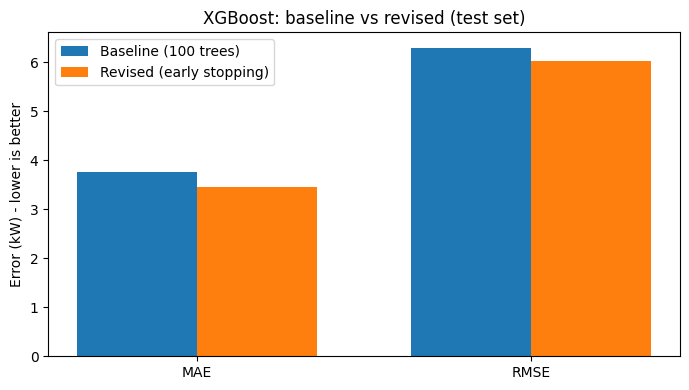

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# ---- improvement check: XGBoost baseline vs revised (same split, same seed) ----
# Baseline = original setting (n_estimators=100). Revised = model trained above (n_estimators=1000, early stopping).
xgb_baseline = XGBRegressor(**{**xgb_model.get_params(), "n_estimators": 100})
xgb_baseline.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

base = calculate_metrics("XGBoost", y_test, xgb_baseline.predict(X_test))
rev = calculate_metrics("XGBoost", y_test, xgb_test_pred)
base["Experiment"] = "Baseline (n_estimators=100)"
rev["Experiment"] = "Revised (n_estimators=1000, early stopping)"

comparison = pd.DataFrame([base, rev])[["Model", "Experiment", "MAE", "RMSE", "R2"]]
comparison["Best iteration"] = [xgb_baseline.best_iteration, xgb_model.best_iteration]

os.makedirs("output", exist_ok=True)
comparison.to_csv("output/model_results.csv", index=False)
display(comparison)

print(f"MAE  change: {base['MAE']:.2f} -> {rev['MAE']:.2f} kW  ({(base['MAE']-rev['MAE'])/base['MAE']*100:+.2f}% lower is better)")
print(f"RMSE change: {base['RMSE']:.2f} -> {rev['RMSE']:.2f} kW  ({(base['RMSE']-rev['RMSE'])/base['RMSE']*100:+.2f}% lower is better)")
print(f"R2   change: {base['R2']:.4f} -> {rev['R2']:.4f}  (difference {rev['R2']-base['R2']:+.4f})")
print("QUICK_MODE:", QUICK_MODE)

# simple chart of the error metrics
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
ax.bar(x - 0.18, [base["MAE"], base["RMSE"]], 0.36, label="Baseline (100 trees)")
ax.bar(x + 0.18, [rev["MAE"], rev["RMSE"]], 0.36, label="Revised (early stopping)")
ax.set_xticks(x); ax.set_xticklabels(["MAE", "RMSE"])
ax.set_ylabel("Error (kW) - lower is better")
ax.set_title("XGBoost: baseline vs revised (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("output/xgb_improvement.png", dpi=150)
plt.show()

try:
    from google.colab import files
    files.download("output/model_results.csv")
    files.download("output/xgb_improvement.png")
except ImportError:
    pass


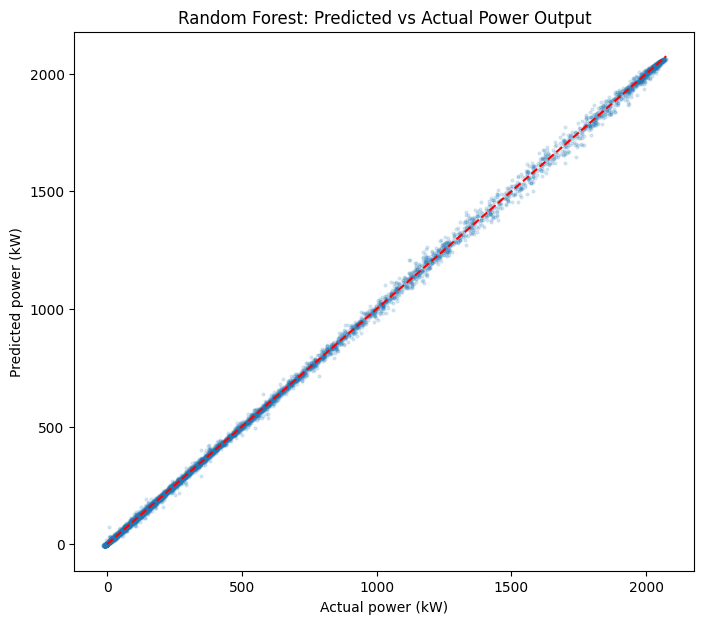

In [20]:
# predicted vs actual power output: random forest

plt.figure(figsize=(8, 7))

plt.scatter(y_test, rf_test_pred, s=4, alpha=0.15, color="tab:blue")
lims = [0, max(y_test.max(), rf_test_pred.max())]
plt.plot(lims, lims, "r--", linewidth=1.5)

plt.xlabel("Actual power (kW)")
plt.ylabel("Predicted power (kW)")
plt.title("Random Forest: Predicted vs Actual Power Output")
plt.show()

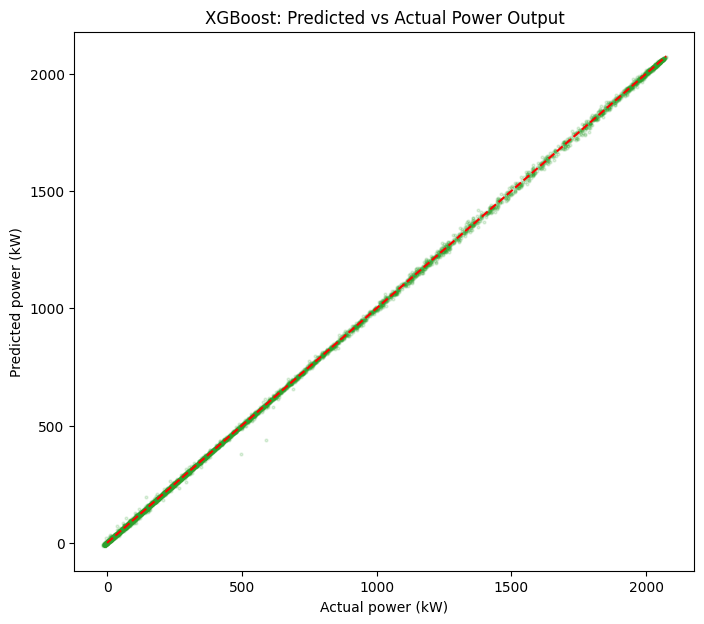

In [21]:
# predicted vs actual power output: XGBoost

plt.figure(figsize=(8, 7))

plt.scatter(y_test, xgb_test_pred, s=4, alpha=0.15, color="tab:green")
lims = [0, max(y_test.max(), xgb_test_pred.max())]
plt.plot(lims, lims, "r--", linewidth=1.5)

plt.xlabel("Actual power (kW)")
plt.ylabel("Predicted power (kW)")
plt.title("XGBoost: Predicted vs Actual Power Output")
plt.show()

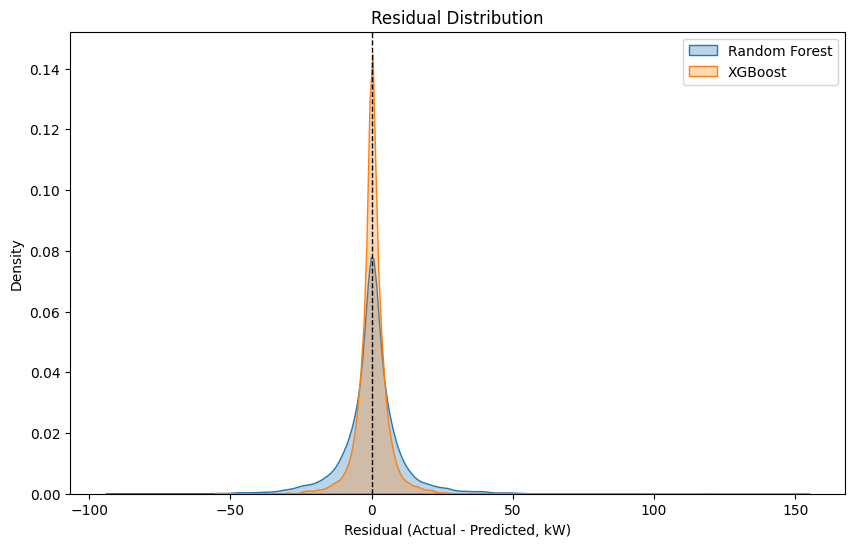

In [22]:
# residual distribution for both models

rf_residuals = y_test.values - rf_test_pred
xgb_residuals = y_test.values - xgb_test_pred

plt.figure(figsize=(10, 6))
sns.kdeplot(rf_residuals, label="Random Forest", fill=True, alpha=0.3)
sns.kdeplot(xgb_residuals, label="XGBoost", fill=True, alpha=0.3)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Residual (Actual - Predicted, kW)")
plt.title("Residual Distribution")
plt.legend()
plt.show()

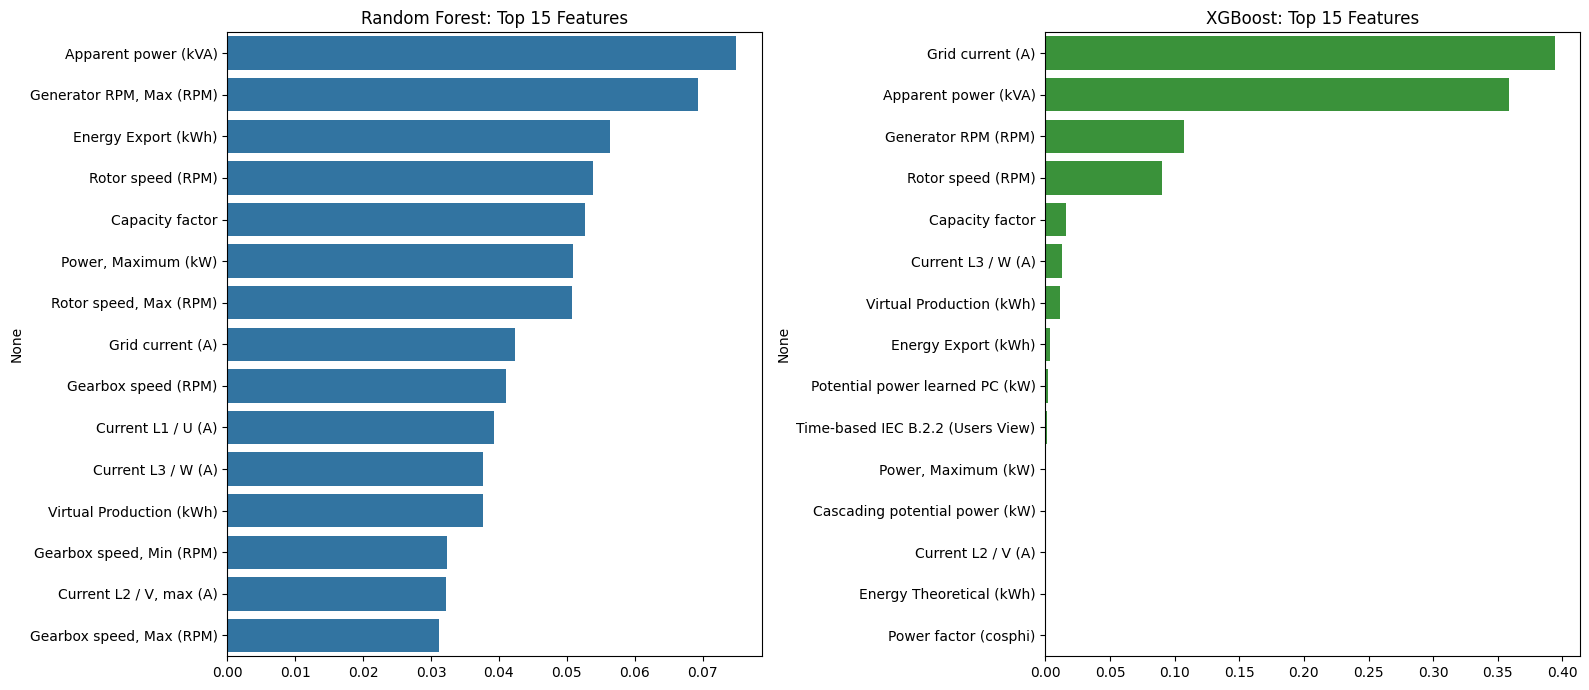

In [23]:
# feature importance (top 15) - useful for maintenance / anomaly-flagging insight

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
xgb_importance = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

sns.barplot(x=rf_importance.values, y=rf_importance.index, ax=axes[0], color="tab:blue")
axes[0].set_title("Random Forest: Top 15 Features")

sns.barplot(x=xgb_importance.values, y=xgb_importance.index, ax=axes[1], color="tab:green")
axes[1].set_title("XGBoost: Top 15 Features")

plt.tight_layout()
plt.show()

In [24]:
# overfitting check

rf_train_pred = rf_model.predict(X_train)
xgb_train_pred = xgb_model.predict(X_train)

rf_train_r2 = r2_score(y_train, rf_train_pred)
rf_test_r2 = r2_score(y_test, rf_test_pred)

xgb_train_r2 = r2_score(y_train, xgb_train_pred)
xgb_test_r2 = r2_score(y_test, xgb_test_pred)

print(f"Random Forest - Train R2: {rf_train_r2:.4f} | Test R2: {rf_test_r2:.4f}")
print(f"XGBoost       - Train R2: {xgb_train_r2:.4f} | Test R2: {xgb_test_r2:.4f}")

Random Forest - Train R2: 0.9999 | Test R2: 0.9997
XGBoost       - Train R2: 1.0000 | Test R2: 0.9999


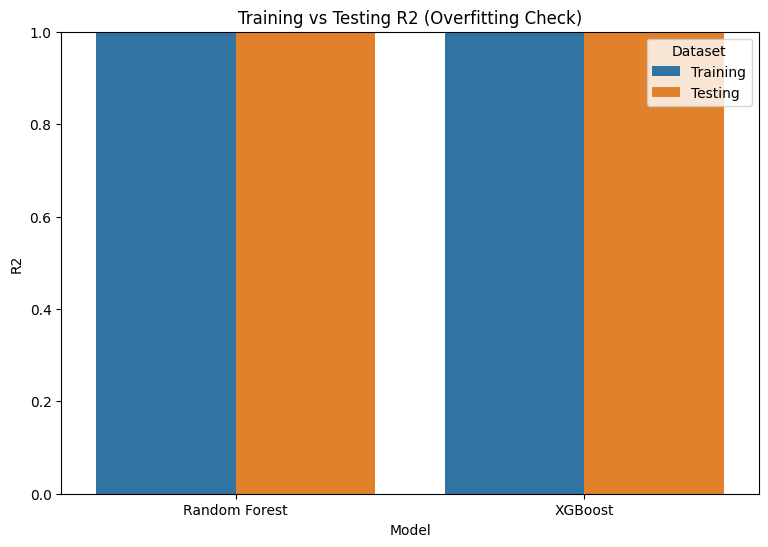

In [25]:
plot_df = pd.DataFrame({
    "Model": ["Random Forest", "Random Forest", "XGBoost", "XGBoost"],
    "Dataset": ["Training", "Testing", "Training", "Testing"],
    "R2": [
        rf_train_r2,
        rf_test_r2,
        xgb_train_r2,
        xgb_test_r2
    ]
})

plt.figure(figsize=(9, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="R2",
    hue="Dataset"
)

plt.ylim(0, 1)
plt.title("Training vs Testing R2 (Overfitting Check)")
plt.show()

In [26]:
if xgb_val_r2 >= rf_val_r2:
    best_model = xgb_model
    best_model_name = "XGBoost"
else:
    best_model = rf_model
    best_model_name = "Random Forest"

print("Selected model:", best_model_name)

Selected model: XGBoost


In [27]:
model_bundle = {
    "model": best_model,
    "feature_columns": list(X.columns),
    "target_column": POWER_COL,
    "model_name": best_model_name
}

joblib.dump(
    model_bundle,
    "kelmarsh_power_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [28]:
#download as .pkl file

import os

file_size = os.path.getsize("kelmarsh_power_model.pkl")

print("File:", "kelmarsh_power_model.pkl")
print("Size:", round(file_size / (1024 * 1024), 2), "MB")

from google.colab import files

if not QUICK_MODE:
    files.download("kelmarsh_power_model.pkl")

File: kelmarsh_power_model.pkl
Size: 5.53 MB
